# Backend Trial
Testing compiler_script modules in nb.

In [135]:
from osgeo import gdal, gdalconst
import matplotlib.pyplot as plt
import numpy as np
import cv2
import time

In [2]:
dataset = gdal.Open('./out2019.tif')

In [3]:
d = gdal.Info('./out2019.tif', format='json')
dataset.GetRasterBand(1).GetStatistics(0,1)

[0.0, 18283.0, 478.88863675832, 920.43229139268]

In [131]:
t = time.time()
stats = [dataset.GetRasterBand(i+1).GetStatistics(True, True) for i in range(dataset.RasterCount)]
vmin, vmax, vmean, vstd = zip(*stats)
min = [0.0] * len(vmin)
max = [4000.0] * len(vmin)
scaleParams = list(zip(*[vmin, vmax, min, max]))
scaleParams

[(0.0, 18283.0, 0.0, 4000.0),
 (0.0, 12272.0, 0.0, 4000.0),
 (0.0, 12252.0, 0.0, 4000.0),
 (0.0, 12211.0, 0.0, 4000.0),
 (0.0, 12444.0, 0.0, 4000.0),
 (0.0, 12528.0, 0.0, 4000.0),
 (0.0, 12583.0, 0.0, 4000.0),
 (0.0, 12536.0, 0.0, 4000.0),
 (0.0, 12557.0, 0.0, 4000.0),
 (0.0, 15368.0, 0.0, 4000.0),
 (0.0, 12010.0, 0.0, 4000.0),
 (0.0, 11748.0, 0.0, 4000.0)]

Band min, Band max, Mean, Std dev

In [132]:
gdal.Info('./out2019.tif', format='json')['bands'][7]['overviews']

[{'size': [5877, 5239]},
 {'size': [2939, 2620]},
 {'size': [1470, 1310]},
 {'size': [735, 655]},
 {'size': [368, 328]}]

In [6]:
#out = gdal.Warp('', dataset, width=256, height=256, outputBounds=[95.127,27.029,94.017,28.015], format='MEM')
#print(out.GetRasterBand(4).ReadAsArray())
#print('====================================================================================================')
#output_type
out = gdal.Translate('',dataset,width=256, height=256, outputBounds=[95.127,27.029,94.017,28.015],scaleParams=scaleParams, format='MEM')
print(out.GetRasterBand(4).ReadAsArray().max())

256
1.1669232845306396


In [136]:
out = gdal.Translate('',dataset,width=256, height=256,outputType=gdalconst.GDT_Int16, outputBounds=[95.127,27.029,94.017,28.015],scaleParams=scaleParams, format='MEM')
print(out.GetRasterBand(4).ReadAsArray().max())

4000


In [128]:
#out = gdal.Warp('', dataset, width=256, height=256, outputBounds=[95.127,27.029,94.017,28.015], format='MEM')
#print(out.GetRasterBand(4).ReadAsArray())
#print('====================================================================================================')
out = gdal.Translate('',dataset,width=256, height=256, outputBounds=[95.127,27.029,94.017,28.015],scaleParams=None, format='MEM')
print(out.GetRasterBand(4).ReadAsArray().max())

12211
62146.880940914154


In [137]:
out.ReadAsArray()

array([[[  0,   0,  22, ...,   0,   0,   0],
        [  0,   0,  22, ...,   0,   0,   0],
        [  0,   1,  28, ...,   0,   0,   0],
        ...,
        [  0,   0,   1, ...,   0,   0,   0],
        [  0,   0,   0, ...,   0,   0,   0],
        [  0,   0,   0, ...,   0,   0,   0]],

       [[  0,   1,  34, ...,   0,   0,   0],
        [  0,   1,  36, ...,   0,   0,   0],
        [  0,   1,  43, ...,   0,   0,   0],
        ...,
        [  0,   0,   2, ...,   0,   0,   0],
        [  0,   0,   0, ...,   0,   0,   0],
        [  0,   0,   0, ...,   0,   0,   0]],

       [[  0,   1,  54, ...,   0,   0,   0],
        [  0,   1,  51, ...,   0,   0,   0],
        [  0,   1,  59, ...,   0,   0,   0],
        ...,
        [  0,   1,   4, ...,   0,   0,   0],
        [  0,   0,   0, ...,   0,   0,   0],
        [  0,   0,   0, ...,   0,   0,   0]],

       ...,

       [[  0,   7, 444, ...,   0,   0,   0],
        [  0,   8, 403, ...,   0,   0,   0],
        [  0,   9, 437, ...,   0,   0,   0

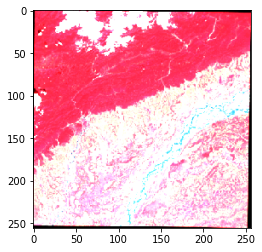

In [138]:
plt.imshow(np.dstack((out.GetRasterBand(8).ReadAsArray(),
                     out.GetRasterBand(4).ReadAsArray(),
                     out.GetRasterBand(3).ReadAsArray()))
           )

In [139]:
# Ver1
def norm(
    x, y=None, z=None,
    op_minR=0, op_maxR=1,
    op_minG=0, op_maxG=1,
    op_minB=0, op_maxB=1,
    clip_minR=None, clip_maxR=None,
    clip_minG=None, clip_maxG=None,
    clip_minB=None, clip_maxB=None,
    ip_minR=None, ip_maxR=None,
    ip_minG=None, ip_maxG=None,
    ip_minB=None, ip_maxB=None):
    clip_flagR = clip_minR is None or clip_maxR is None
    ip_flagR = ip_minR is None or ip_maxR is None
    clip_flagG = clip_minG is None or clip_maxG is None
    ip_flagG = ip_minG is None or ip_maxG is None
    clip_flagB = clip_minB is None or clip_maxB is None
    ip_flagB = ip_minB is None or ip_maxB is None
    if y is None and z is None:
        indices = np.where(x==0)
        if not ip_flagR:
            x = (x-ip_minR)/(ip_maxR-ip_minR)
            x = ((op_maxR-op_minR)*x)+op_minR
        x[indices] = 0
        if not clip_flagR:
            x = np.clip(x, clip_minR, clip_maxR)
        if not ip_flagR:
            x *= 255.0
        return x
    indices1 = np.where(x==0)
    indices2 = np.where(y==0)
    indices3 = np.where(z==0)
    if not ip_flagR:
        x = (x-ip_minR)/(ip_maxR-ip_minR)
        x = ((op_maxR-op_minR)*x)+op_minR
    if not ip_flagG:
        y = (x-ip_minG)/(ip_maxG-ip_minG)
        y = ((op_maxG-op_minG)*y)+op_minG
    if not ip_flagB:
        z = (x-ip_minB)/(ip_maxB-ip_minB)
        z = ((op_maxB-op_minB)*z)+op_minB
    if not clip_flagR:
        x = np.clip(x, clip_minR, clip_maxR)
    if not clip_flagG:
        y = np.clip(y, clip_minG, clip_maxG)
    if not clip_flagB:
        z = np.clip(z, clip_minB, clip_maxB)
    if not ip_flagR:
        x *= 255.0
    if not ip_flagG:
        y *= 255.0
    if not ip_flagB:
        z *= 255.0
    x[indices1] = 0
    y[indices2] = 0
    z[indices3] = 0
    return x, y, z

In [123]:
# Ver2
def single_band_norm(
    x,
    op_min=0, op_max=1,
    ip_min=None, ip_max=None,
    clip_min=None, clip_max=None
    ):
    clip_flag = clip_min is None or clip_max is None
    ip_flag = ip_min is None or ip_max is None
    indices = np.where(x==0)
    if not ip_flag:
        x = (x-ip_min)/(ip_max-ip_min)
        x = ((op_max-op_min)*x)+op_min
    x[indices] = 0
    if not clip_flag:
        x = np.clip(x, clip_min, clip_max)
    x = x*255.0 if not ip_flag else x
    return x

def norm(
    x, y=None, z=None,
    op_minR=0, op_maxR=1,
    op_minG=0, op_maxG=1,
    op_minB=0, op_maxB=1,
    clip_minR=None, clip_maxR=None,
    clip_minG=None, clip_maxG=None,
    clip_minB=None, clip_maxB=None,
    ip_minR=None, ip_maxR=None,
    ip_minG=None, ip_maxG=None,
    ip_minB=None, ip_maxB=None
    ):
    if y is None and z is None:
        return single_band_norm(
                x=x,
                op_min=op_minR, op_max=op_maxR,
                ip_min=ip_minR, ip_max=ip_maxR,
                clip_min=clip_minR, clip_max=clip_maxR
                )
    x = single_band_norm(
                x=x,
                op_min=op_minR, op_max=op_maxR,
                ip_min=ip_minR, ip_max=ip_maxR,
                clip_min=clip_minR, clip_max=clip_maxR
                )
    y = single_band_norm(
                x=y,
                op_min=op_minG, op_max=op_maxG,
                ip_min=ip_minG, ip_max=ip_maxG,
                clip_min=clip_minG, clip_max=clip_maxG
                )
    z = single_band_norm(
                x=z,
                op_min=op_minB, op_max=op_maxB,
                ip_min=ip_minB, ip_max=ip_maxB,
                clip_min=clip_minB, clip_max=clip_maxB
                )
    return x, y, z

In [115]:
GLOBAL_MIN = 0
GLOBAL_MAX = 4000
class B():
    def __init__(self,dataset=None, band_no=0, band=None, min=0, max=4000):
        if dataset is None:
            self._band = band.astype(np.double)
        else:
            #self._band = norm(x=np.array(dataset.GetRasterBand(band_no).ReadAsArray()),ip_minR=min,ip_maxR=max)
            self._band = dataset.GetRasterBand(band_no).ReadAsArray().astype(np.double)
        #print('=====',self._band.min(),self._band.max(),self._band.dtype)
    
    @property
    def band(self):
        return self._band
    
    def __repr__(self):
        return self._band
    
    def __getitem__(self, index):
        return self.band[index]
    
    #Statistical Ops
    def mean(self):
        return np.mean(self._band)
    
    def std(self):
        return np.std(self._band)
    
    #Arithmetic Operations
    def __add__(self,y):
        return B(band=self._band+y.band)
    
    def __sub__(self, y):
        return B(band=self._band-y.band)
    
    def __mul__(self, y):
        if isinstance(y,B):
            return B(band=np.multiply(self._band,y.band))
        else:
            return B(band=self._band * y)
    
    def __truediv__(self, y):
        if isinstance(y,B):
            return B(band=np.divide(self._band, y.band, out=np.zeros_like(self._band), where=y.band!=0, casting="unsafe"))
        else:
            return B(band=self._band/y)
    
    #Bitwise Operators
    def __and__(self, y):
        return B(band=np.bitwise_and(self._band,y))
    
    def __or__(self, y):
        return B(band=np.bitwise_or(self._band,y))
    
    def __xor__(self, y):
        return B(band=np.bitwise_xor(self._band,y))
    
    def __invert__(self, y):
        return B(band=np.invert(self._band,y))
    
    #Comparison Operators    
    def __gt__(self, y):
        return B(band=np.array(self._band>y))
    
    def __ge__(self, y):
        return B(band=np.array(self._band>=y))

    def __lt__(self, y):
        return B(band=np.array(self._band<y))
    
    def __le__(self, y):
        return B(band=np.array(self._band<=y))
    
    def __eq__(self, y):
        return B(band=np.array(self._band==y))
    
    def __ne__(self, y):
        return B(band=np.array(self._band!=y))
    
    #Convolution Operations    
    def conv2D(self, kernel, padding=0, strides=1):
        image = self.band
        kernel = np.flipud(np.fliplr(kernel))
        xKernShape = kernel.shape[0]
        yKernShape = kernel.shape[1]
        xImgShape = image.shape[0]
        yImgShape = image.shape[1]
        xOutput = int(((xImgShape - xKernShape + 2 * padding) / strides) + 1)
        yOutput = int(((yImgShape - yKernShape + 2 * padding) / strides) + 1)
        output = np.zeros((xOutput, yOutput))
        if padding != 0:
            imagePadded = np.zeros((image.shape[0] + padding*2, image.shape[1] + padding*2))
            imagePadded[int(padding):int(-1 * padding), int(padding):int(-1 * padding)] = image
        else:
            imagePadded = image
        for y in range(image.shape[1]):
            if y > image.shape[1] - yKernShape:
                break
            if y % strides == 0:
                for x in range(image.shape[0]):
                    if x > image.shape[0] - xKernShape:
                        break
                    try:
                        if x % strides == 0:
                            output[x, y] = (kernel * imagePadded[x: x + xKernShape, y: y + yKernShape]).sum()
                    except:
                        break
        return B(band=output)

In [140]:
def setup(
    R, G=None, B=None,
    weight=None, 
    op_minR=0, op_maxR=1, 
    op_minG=0, op_maxG=1, 
    op_minB=0, op_maxB=1,
    clip_minR=None, clip_maxR=None,
    clip_minG=None, clip_maxG=None,
    clip_minB=None, clip_maxB=None,
    ip_minR=None, ip_maxR=None, 
    ip_minG=None, ip_maxG=None, 
    ip_minB=None, ip_maxB=None,
    cmap=None,
    cmap_order=1
    ):
    if (np.max(R.band)==0 and G is None and B is None) or (np.max(R.band)==0 and np.max(G.band)==0 and np.max(B.band)==0):
        im = np.zeros((256,256,4))
        img = Image.fromarray(im, mode='RGBA')
        response = HttpResponse(content_type="image/png")
        img.save(response, "PNG")
        return response
    if weight is None:
        weight = [1,1,1]
    if G is None and B is None:
        im  = weight[0] * R.band
        if cmap is not None and cmap_order==1:
            im = apply_cmap(im, cmap)
        im = np.array(norm(
            x = im,
            ip_minR=ip_minR, ip_maxR=ip_maxR,
            clip_minR=clip_minR, clip_maxR=clip_maxR,
            op_minR=op_minR, op_maxR=op_maxR
        ))
        if cmap is not None and cmap_order==0:
            im = apply_cmap(im, cmap)
    else:
        im = np.dstack(norm(
            R.band,G.band,B.band,
            op_minR=op_minR, op_maxR=op_maxR,
            op_minG=op_minG, op_maxG=op_maxG,
            op_minB=op_minB, op_maxB=op_maxB,
            clip_minR=clip_minR, clip_maxR=clip_maxR,
            clip_minG=clip_minG, clip_maxG=clip_maxG,
            clip_minB=clip_minB, clip_maxB=clip_maxB,
            ip_minR=ip_minR, ip_maxR=ip_maxR,
            ip_minG=ip_minG, ip_maxG=ip_maxG,
            ip_minB=ip_minB, ip_maxB=ip_maxB
        ))
    return im.astype(np.uint8)

-0.562962962962963 1.0
0 255


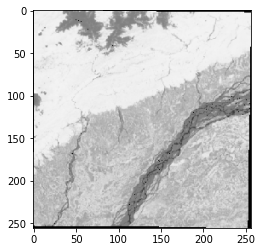

In [142]:
g = B(dataset=out, band_no=4)
#print(g.band.min(),g.band.max())
b = B(dataset=out, band_no=8)
#print(b.band.min(),b.band.max())
ndvi = (b-g)/(b+g)
print(ndvi.band.min(),ndvi.band.max())
response = setup(
  ndvi,
  ip_minR = -1, ip_maxR = 1
)
print(response.min(),response.max())
plt.imshow(response, cmap='gray')

0.0 4000.0 256.56700134277344 275.4227587025232
0.0 4000.0 240.13487243652344 285.266004746603
0.0 4000.0 786.7014312744141 260.3515851493844
0 255


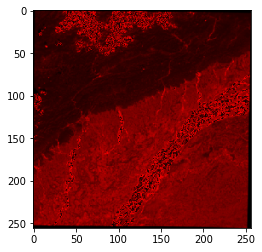

In [148]:
r = B(dataset=out, band_no=3)
print(r.band.min(),r.band.max(),r.band.mean(),r.band.std())
g = B(dataset=out, band_no=4)
print(g.band.min(),g.band.max(),g.band.mean(),g.band.std())
b = B(dataset=out, band_no=8)
print(b.band.min(),b.band.max(),b.band.mean(),b.band.std())
response = setup(
  r,g,b,
  ip_minR=0,ip_maxR=500,
  ip_minG=0,ip_maxG=500,
  ip_minB=0,ip_maxB=500,
)
print(response.min(),response.max())
plt.imshow(response)

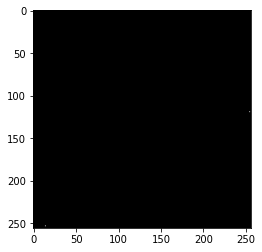

In [126]:
g = B(dataset=out, band_no=4)
b = B(dataset=out, band_no=8)
ndvi = (b-g)/(b+g)
response = setup(
  ndvi,
)

plt.imshow(response, cmap='gray')

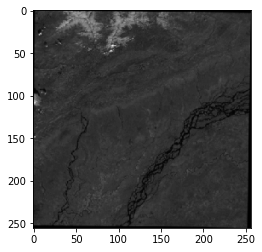

In [127]:
r = B(dataset=out,band_no=8)

plt.imshow(r.band,cmap='gray')

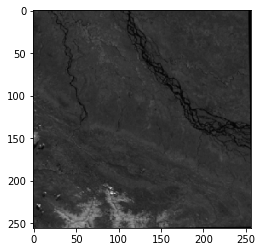

In [67]:
r = B(dataset=out,band_no=8)

plt.imshow(r.band,cmap='gray')

In [6]:
def apply_cmap(im, cmap):
    if cmap=='red':
        return np.dstack((np.zeros(im.shape),np.zeros(im.shape),im))
    elif cmap=='green':
        return np.dstack((np.zeros(im.shape),im,np.zeros(im.shape)))
    elif cmap=='blue':
        return np.dstack((im,np.zeros(im.shape),np.zeros(im.shape)))
    else:
        return im

G and B None


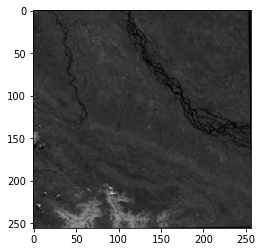

In [70]:
r = B(dataset=out,band_no=8)

plt.imshow(setup(R=r),cmap='gray')

In [119]:
r = B(dataset=out, band_no=8)
g = B(dataset=out, band_no=4)
b = B(dataset=out, band_no=3)

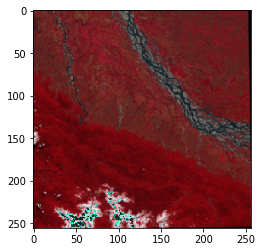

In [112]:
plt.imshow(np.dstack((r.band,g.band,b.band)).astype(np.uint8))

In [120]:
response = setup(
  R=b,G=g,B=r,
  ip_minR=0,ip_maxR=12536,
  ip_minB=0,ip_maxB=12252,
  ip_minG=0,ip_maxG=12211,
)

0.0 1249.7040000000002
0.0 1245.5220000000002
0.0 1278.672
X: [[0.00458902 0.00484939 0.00532131 ... 0.         0.         0.        ]
 [0.00706254 0.00740428 0.00785179 ... 0.         0.         0.        ]
 [0.00736359 0.00765651 0.00825048 ... 0.         0.         0.        ]
 ...
 [0.00144017 0.00198532 0.00214805 ... 0.00174936 0.00170054 0.00187141]
 [0.00169241 0.00231078 0.00183073 ... 0.00104962 0.00096011 0.00096011]
 [0.00146458 0.00275016 0.00230265 ... 0.         0.         0.        ]]
Y: [[3.75810631e-07 3.97133220e-07 4.35780412e-07 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [5.78375226e-07 6.06361124e-07 6.43009324e-07 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [6.03029470e-07 6.27017382e-07 6.75659538e-07 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [1.17940570e-07 1.62584741e-07 1.75911359e-07 ... 1.43261145e-07
  1.39263159e-07 1.53256108e-07]
 [1.38596828e-07 1.89237977e-07 1.49924454e-07 ... 8.59566868e-08
  7.86270469e-08 7.86270

In [22]:
r = B(dataset=out, band_no=8)
g = B(dataset=out, band_no=4)
b = B(dataset=out, band_no=3)
response = setup(
  R=r,G=g,B=b,
  ip_minR=0,ip_maxR=2500,
  ip_minB=0,ip_maxB=2500,
  ip_minG=0,ip_maxG=4000,
)

None
None
None
0.0 1278.672
0.0 1245.5220000000002
0.0 1249.7040000000002
0.0 130.42454400000003
0.0 0.032606136
0.0 0.05216981760000001


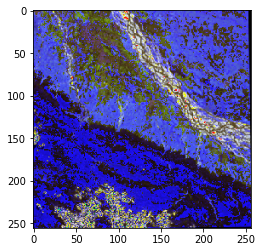

In [122]:
plt.imshow(response.astype(np.uint8))

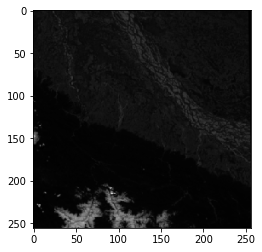

In [34]:
plt.imshow(setup(R=g),cmap='gray')

In [39]:
print(r.band)
print('=================')
print(g.band)

[[0.7296 0.7544 0.802  ... 0.     0.     0.    ]
 [1.0624 1.0956 1.188  ... 0.     0.     0.    ]
 [1.0448 0.8376 1.0596 ... 0.     0.     0.    ]
 ...
 [0.5184 0.5696 0.6796 ... 0.8808 0.8428 0.8608]
 [0.6696 0.7568 0.5128 ... 0.4604 0.4424 0.4208]
 [0.5504 1.128  0.9108 ... 0.     0.     0.    ]]
[[0.1684 0.1768 0.1864 ... 0.     0.     0.    ]
 [0.2668 0.2812 0.2684 ... 0.     0.     0.    ]
 [0.302  0.3792 0.3324 ... 0.     0.     0.    ]
 ...
 [0.0412 0.05   0.0576 ... 0.0472 0.0452 0.0504]
 [0.0492 0.0624 0.0424 ... 0.0288 0.0264 0.026 ]
 [0.0376 0.074  0.0592 ... 0.     0.     0.    ]]


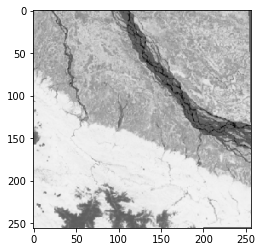

In [25]:
ndvi = (r-g)/(r+g)
plt.imshow(setup(R=ndvi),cmap='gray')

In [44]:
ndvi.band

array([[0.62494432, 0.62027491, 0.62282477, ..., 0.        , 0.        ,
        0.        ],
       [0.59855552, 0.59151656, 0.63141994, ..., 0.        , 0.        ,
        0.        ],
       [0.55152955, 0.37672584, 0.52241379, ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.85275197, 0.83860555, 0.84373304, ..., 0.89827586, 0.8981982 ,
        0.88937665],
       [0.86310518, 0.84765625, 0.84726225, ..., 0.88225675, 0.88737201,
        0.88361683],
       [0.87210884, 0.87687188, 0.87793814, ..., 0.        , 0.        ,
        0.        ]])

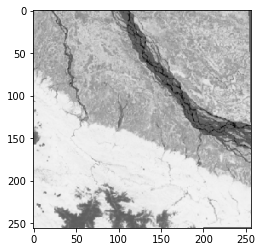

In [27]:
ndvi = (r-g)/(r+g)
plt.imshow(setup(R=ndvi,maxR=0.5),cmap='gray')